# 03 · Entrenar bien redes profundas: generalización, regularización y estrategia

El notebook 02 mostró cómo *aprende* una red: la retropropagación calcula los gradientes y un optimizador los sigue cuesta abajo. Esa es la mitad fácil. La mitad difícil es que una pérdida de entrenamiento baja no es el objetivo. El objetivo es una red que funcione con datos que **nunca ha visto**.

Este notebook trata del oficio que hay entre "el código se ejecuta" y "el modelo es bueno":

| Sección | Pregunta | Herramientas |
|---|---|---|
| 1 | ¿Cómo mido lo que de verdad me importa? | particiones de entrenamiento / validación / prueba |
| 2-3 | ¿Mi modelo es demasiado simple o demasiado complejo? | barrido de capacidad, sesgo y varianza, curvas de aprendizaje |
| 4 | Mi modelo memoriza el conjunto de entrenamiento. ¿Y ahora qué? | decaimiento de pesos L2, dropout, parada temprana |
| 5 | Las redes profundas entrenan lento o divergen. ¿Por qué? | normalización por lotes |
| 6 | ¿Qué tamaño de lote y qué calendario de tasa de aprendizaje? | minilotes, calentamiento, decaimiento coseno |
| 7 | ¿Cómo elijo los hiperparámetros? | búsqueda en cuadrícula frente a búsqueda aleatoria |
| 8 | ¿En qué debería trabajar ahora? | análisis de errores, desajuste entre entrenamiento y validación |

Todo se ejecuta en una CPU en pocos minutos, con dos conjuntos de datos que vienen incluidos en scikit-learn: las "lunas" en 2D (para ver las fronteras de decisión) y dígitos manuscritos de 8×8.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, random, copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split

torch.manual_seed(0); np.random.seed(0); random.seed(0)
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def train(model, X, y, Xd=None, yd=None, epochs=100, lr=1e-3, wd=0.0, batch=32, schedule=None, keep_best=False):
    # un bucle de entrenamiento reutilizable: Adam (+ decaimiento de pesos desacoplado opcional), minilotes, historial de exactitud de entrenamiento/validación
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps_per_epoch = math.ceil(len(X) / batch)
    hist = {"train": [], "dev": [], "loss": [], "lr": []}
    best = (-1, None, 0)
    step = 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            if schedule:
                for gp in opt.param_groups:
                    gp["lr"] = schedule(step, epochs * steps_per_epoch) * lr
            b = perm[i:i + batch]
            loss = F.cross_entropy(model(X[b]), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            hist["loss"].append(loss.item()); hist["lr"].append(opt.param_groups[0]["lr"]); step += 1
        hist["train"].append(accuracy(model, X, y))
        if Xd is not None:
            hist["dev"].append(accuracy(model, Xd, yd))
            if keep_best and hist["dev"][-1] > best[0]:
                best = (hist["dev"][-1], copy.deepcopy(model.state_dict()), ep)
    if keep_best:
        model.load_state_dict(best[1]); hist["best_epoch"] = best[2]
    return hist

def mlp(sizes, dropout=0.0, batchnorm=False, act=nn.ReLU):
    layers = []
    for a, b in zip(sizes[:-2], sizes[1:-1]):
        layers.append(nn.Linear(a, b))
        if batchnorm: layers.append(nn.BatchNorm1d(b))
        layers.append(act())
        if dropout: layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(sizes[-2], sizes[-1]))
    return nn.Sequential(*layers)

## 1. Entrenamiento, validación y prueba: medir lo que importa

Un modelo solo es útil con datos que no ha visto, así que reservamos una parte de los datos. En la práctica necesitamos **tres** conjuntos:

| Conjunto | Se usa para | Regla |
|---|---|---|
| **entrenamiento** | ajustar los pesos | el optimizador lo ve en cada paso |
| **validación** (dev) | elegir *todo lo demás*: arquitectura, tasa de aprendizaje, regularización, cuándo parar | míralo tantas veces como quieras |
| **prueba** (test) | una estimación final y sin sesgo | míralo **una sola vez**, al final |

¿Por qué no basta con entrenamiento y prueba? Porque cada decisión que tomas mirando una puntuación es una forma de entrenamiento. Prueba 50 configuraciones, quédate con la mejor puntuación en prueba, y esa puntuación será optimista: has ajustado el conjunto de prueba a mano. El conjunto de validación absorbe ese optimismo para que el de prueba siga siendo honesto.

Dos reglas más de la práctica: los conjuntos de validación y prueba deben venir de la **misma distribución que los datos que verás en producción** (la sección 8 muestra qué pasa cuando no es así), y con conjuntos de datos grandes pueden ser un porcentaje pequeño de los datos: 10.000 ejemplos de validación miden la exactitud con un margen de unos ±0,3 %, tengas 100 mil o 100 millones de ejemplos de entrenamiento.

In [2]:
digits = load_digits()
X_all = torch.tensor(digits.data / 16.0, dtype=torch.float32)          # 1.797 imágenes, aplanadas a 64 entradas
y_all = torch.tensor(digits.target)
idx_tmp, idx_test = train_test_split(np.arange(len(y_all)), test_size=0.2, random_state=0, stratify=y_all)
idx_train, idx_dev = train_test_split(idx_tmp, test_size=0.25, random_state=0, stratify=y_all[idx_tmp])
Xtr, ytr, Xdev, ydev, Xte, yte = X_all[idx_train], y_all[idx_train], X_all[idx_dev], y_all[idx_dev], X_all[idx_test], y_all[idx_test]
print(f"entrenamiento {len(ytr)}   validación {len(ydev)}   prueba {len(yte)}   (60/20/20, estratificado por dígito)")

entrenamiento 1077   validación 360   prueba 360   (60/20/20, estratificado por dígito)


## 2. Subajuste y sobreajuste

La **capacidad** es qué tan complicada puede ser la función que un modelo es capaz de representar. Con muy poca, el modelo no puede captar el patrón (**subajuste**, o **sesgo** alto). Con demasiada y pocos datos, se ajusta al ruido de la muestra de entrenamiento concreta (**sobreajuste**, o **varianza** alta).

El conjunto de las dos lunas lo hace visible. Entrenamos MLP cada vez más anchos con 200 puntos ruidosos, durante el tiempo suficiente para que cada uno se ajuste a los datos de entrenamiento lo mejor que pueda, y miramos el error de entrenamiento y el de validación.

7 modelos entrenados en 16 s


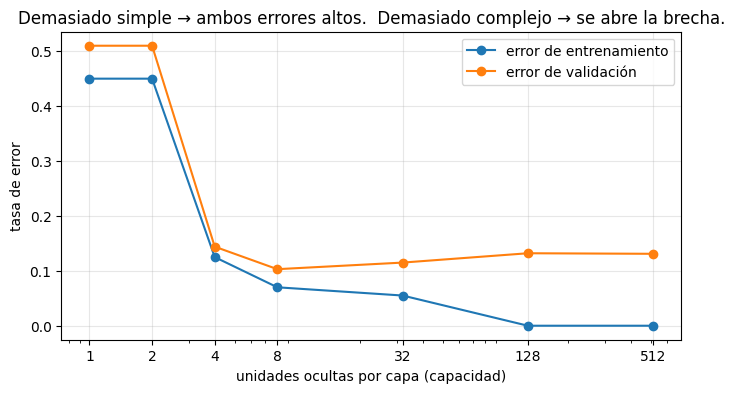

In [3]:
Xm, ym = make_moons(n_samples=1200, noise=0.35, random_state=0)
Xm, ym = torch.tensor(Xm, dtype=torch.float32), torch.tensor(ym)
Xm_tr, ym_tr, Xm_dev, ym_dev = Xm[:200], ym[:200], Xm[200:], ym[200:]

widths = [1, 2, 4, 8, 32, 128, 512]
moon_models, tr_err, dev_err = {}, [], []
t0 = time.time()
for w in widths:
    torch.manual_seed(0)
    m = mlp([2, w, w, 2])
    train(m, Xm_tr, ym_tr, epochs=600, lr=3e-3, batch=200)
    moon_models[w] = m
    tr_err.append(1 - accuracy(m, Xm_tr, ym_tr)); dev_err.append(1 - accuracy(m, Xm_dev, ym_dev))
print(f"{len(widths)} modelos entrenados en {time.time() - t0:.0f} s")

plt.figure(figsize=(8, 4))
plt.plot(widths, tr_err, "o-", label="error de entrenamiento"); plt.plot(widths, dev_err, "o-", label="error de validación")
plt.xscale("log"); plt.xticks(widths, widths); plt.xlabel("unidades ocultas por capa (capacidad)"); plt.ylabel("tasa de error")
plt.title("Demasiado simple → ambos errores altos.  Demasiado complejo → se abre la brecha."); plt.legend(); plt.grid(alpha=0.3); plt.show()

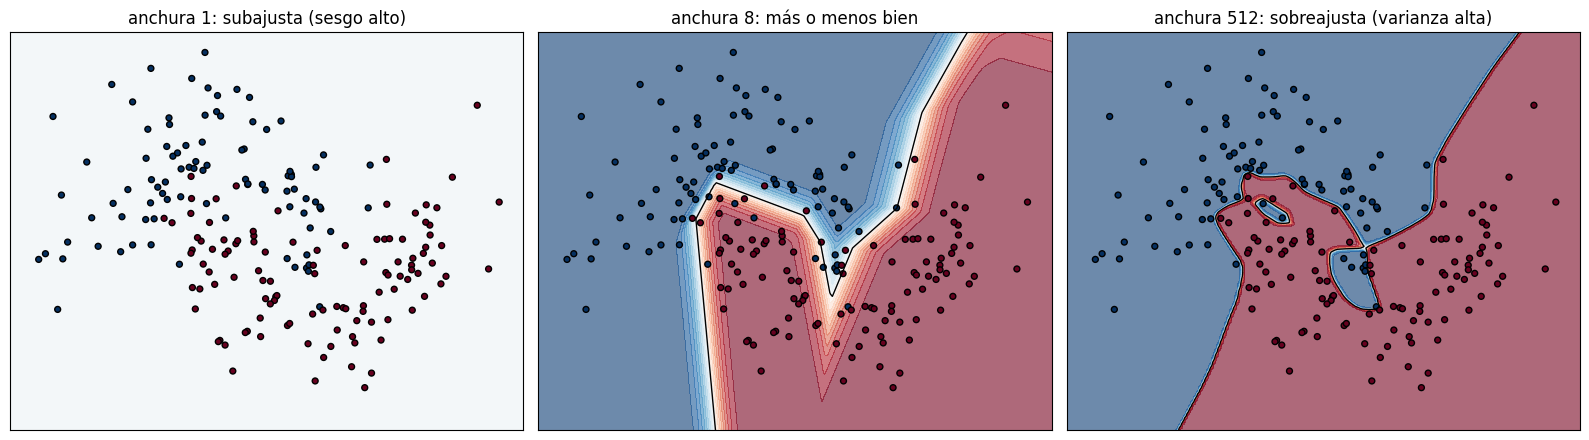

In [4]:
def plot_boundary(ax, model, X, y, title):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    model.eval()
    with torch.no_grad():
        p = model(grid).softmax(1)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, p, levels=20, cmap="RdBu_r", alpha=0.6)
    ax.contour(xx, yy, p, levels=[0.5], colors="k", linewidths=1)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", edgecolors="k", s=18)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, w, label in zip(axes, [1, 8, 512], ["subajusta (sesgo alto)", "más o menos bien", "sobreajusta (varianza alta)"]):
    plot_boundary(ax, moon_models[w], Xm_tr, ym_tr, f"anchura {w}: {label}")
plt.tight_layout(); plt.show()

La red más ancha talla pequeñas islas alrededor de puntos ruidosos concretos: ha memorizado la muestra de entrenamiento. La más estrecha está tan limitada que no puede representar la curva en absoluto: aquí su única unidad ReLU quedó inactiva ("muerta", notebook 01), así que predice la misma clase casi en todas partes y se queda en torno a un 50 % de error.

## 3. Diagnosticar el sesgo y la varianza

Rara vez se puede dibujar la frontera de decisión, pero siempre se pueden comparar cuatro números:

| | Ejemplo A | Ejemplo B | Ejemplo C | Ejemplo D |
|---|---|---|---|---|
| error de referencia (el mejor alcanzable, p. ej. humano) | 1 % | 1 % | 1 % | 1 % |
| error de entrenamiento | 1,5 % | 12 % | 12 % | 1,5 % |
| error de validación | 11 % | 13 % | 25 % | 2 % |
| diagnóstico | **varianza alta** | **sesgo alto** | **ambos** | bien |

* **Sesgo evitable** = error de entrenamiento − error de referencia. Se corrige con un modelo más grande, más entrenamiento o una arquitectura mejor.
* **Varianza** = error de validación − error de entrenamiento. Se corrige con más datos, regularización (sección 4), aumento de datos o un modelo más pequeño.

Las **curvas de aprendizaje** dan una segunda vista: se entrena el mismo modelo con porciones cada vez mayores del conjunto de entrenamiento. Si las dos curvas han convergido en un error alto, más datos no ayudarán (sesgo). Si hay una brecha grande que todavía se está cerrando, sí ayudarán.

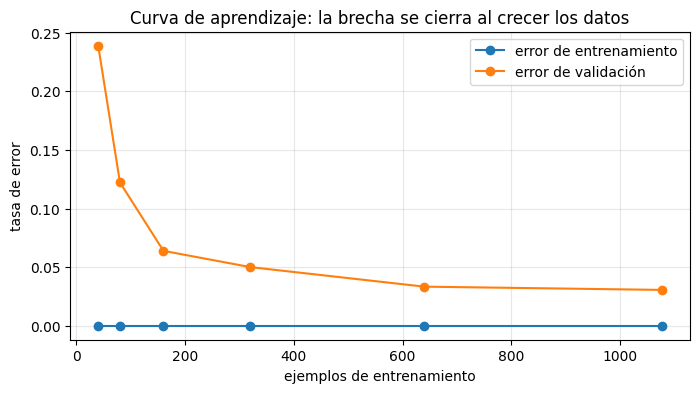

   40 ejemplos   error de entrenamiento  0.0%   error de validación 23.9%
   80 ejemplos   error de entrenamiento  0.0%   error de validación 12.2%
  160 ejemplos   error de entrenamiento  0.0%   error de validación  6.4%
  320 ejemplos   error de entrenamiento  0.0%   error de validación  5.0%
  640 ejemplos   error de entrenamiento  0.0%   error de validación  3.3%
 1077 ejemplos   error de entrenamiento  0.0%   error de validación  3.1%


In [5]:
sizes = [40, 80, 160, 320, 640, len(ytr)]
lc_tr, lc_dev = [], []
for n in sizes:
    torch.manual_seed(0)
    m = mlp([64, 256, 256, 10])
    train(m, Xtr[:n], ytr[:n], epochs=150, lr=1e-3, batch=32)
    lc_tr.append(1 - accuracy(m, Xtr[:n], ytr[:n])); lc_dev.append(1 - accuracy(m, Xdev, ydev))
plt.figure(figsize=(8, 4))
plt.plot(sizes, lc_tr, "o-", label="error de entrenamiento"); plt.plot(sizes, lc_dev, "o-", label="error de validación")
plt.xlabel("ejemplos de entrenamiento"); plt.ylabel("tasa de error"); plt.title("Curva de aprendizaje: la brecha se cierra al crecer los datos")
plt.legend(); plt.grid(alpha=0.3); plt.show()
for n, a, b in zip(sizes, lc_tr, lc_dev):
    print(f"{n:5d} ejemplos   error de entrenamiento {a:5.1%}   error de validación {b:5.1%}")

El error de entrenamiento es cero en todos los tamaños: esta red tiene capacidad de sobra. El error de validación sigue bajando a medida que crecen los datos, así que este modelo está limitado por la **varianza**, y más datos o regularización son la palanca correcta.

## 4. Regularización: la caja de herramientas contra el sobreajuste

Para que el sobreajuste sea evidente, dejamos a propósito sin datos a una red grande: 64 → 512 → 512 → 10 (unos 300.000 parámetros) entrenada con solo **200** dígitos. Después probamos los remedios habituales, uno a uno.

**Regularización L2 / decaimiento de pesos.** Se suma $\frac{\lambda}{2}\sum w^2$ a la pérdida o, lo que es equivalente, se encoge un poco cada peso en cada paso: $w \leftarrow w - \eta(\nabla_w \mathcal{L} + \lambda w)$. Los pesos grandes permiten a la red construir funciones abruptas y onduladas; mantenerlos pequeños mantiene la función suave. Con Adam, la versión "desacoplada" (**AdamW**, la que usamos aquí) funciona mejor que sumar la penalización a la pérdida.

**Dropout** (Srivastava et al., 2014). Durante el entrenamiento, cada unidad oculta se pone a cero con probabilidad $p$ y las supervivientes se escalan por $1/(1-p)$ para que la activación esperada no cambie. Ninguna unidad puede depender de que otra unidad concreta esté presente, así que la red aprende características redundantes y más robustas. Se comporta como entrenar un enorme conjunto de redes adelgazadas que comparten pesos. En la prueba, el dropout se desactiva.

**Parada temprana.** Se vigila la exactitud de validación durante el entrenamiento y se conservan los pesos de la mejor época. Gratis, simple y casi siempre vale la pena.

In [6]:
class MyDropout(nn.Module):
    # dropout "invertido", escrito a mano; se comporta exactamente como nn.Dropout
    def __init__(self, p):
        super().__init__(); self.p = p
    def forward(self, x):
        if not self.training or self.p == 0:
            return x                                       # en la prueba: no hace nada
        mask = (torch.rand_like(x) > self.p).float()
        return x * mask / (1 - self.p)                     # reescalado para que E[salida] = x

d = MyDropout(0.5); d.train()
x = torch.ones(1, 10)
print("modo entrenamiento:", d(x).numpy().round(1), "  media sobre muchas extracciones:", round(d(torch.ones(10000, 10)).mean().item(), 3))
d.eval(); print("modo evaluación   :", d(x).numpy().round(1))

modo entrenamiento: [[0. 2. 0. 0. 0. 2. 0. 0. 0. 2.]]   media sobre muchas extracciones: 1.002
modo evaluación   : [[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]


5 modelos entrenados en 46 s

                         exact. entr. exact. val.
sin regularización             100.0%       94.4%
decaimiento de pesos L2        100.0%       95.0%
dropout 0.5                    100.0%       95.6%
parada temprana                100.0%       94.7%   (mejor época 185)
dropout + L2 + parada          100.0%       95.8%   (mejor época 196)


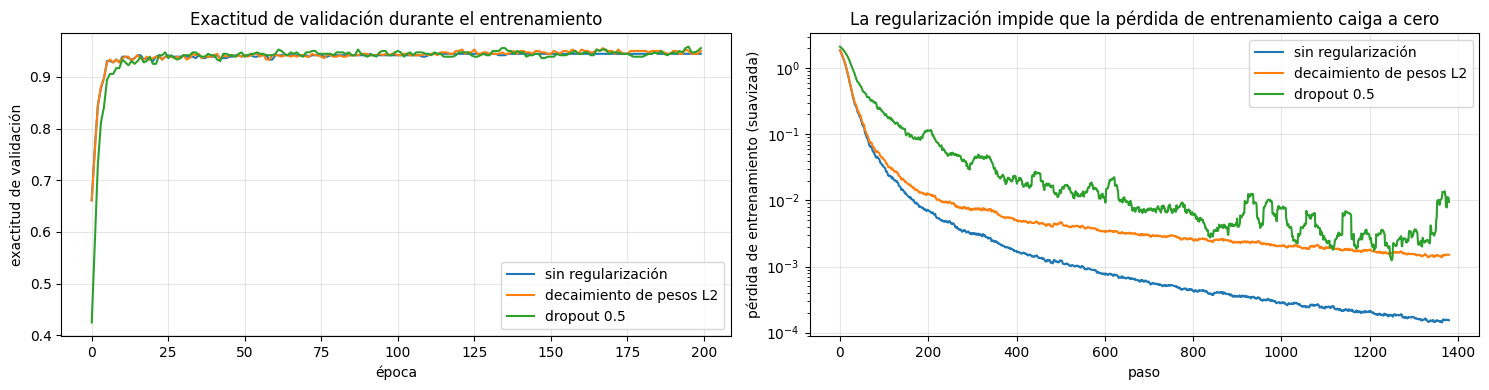

In [7]:
Xs, ys = Xtr[:200], ytr[:200]                                         # el conjunto de entrenamiento escaso
configs = {
    "sin regularización":       dict(model=lambda: mlp([64, 512, 512, 10]),              wd=0.0, keep_best=False),
    "decaimiento de pesos L2":         dict(model=lambda: mlp([64, 512, 512, 10]),              wd=0.5, keep_best=False),
    "dropout 0.5":             dict(model=lambda: mlp([64, 512, 512, 10], dropout=0.5), wd=0.0, keep_best=False),
    "parada temprana":          dict(model=lambda: mlp([64, 512, 512, 10]),              wd=0.0, keep_best=True),
    "dropout + L2 + parada":    dict(model=lambda: mlp([64, 512, 512, 10], dropout=0.5), wd=0.5, keep_best=True),
}
reg_hist, reg_models = {}, {}
t0 = time.time()
for name, cfg in configs.items():
    torch.manual_seed(0)
    m = cfg["model"]()
    reg_hist[name] = train(m, Xs, ys, Xdev, ydev, epochs=200, lr=1e-3, wd=cfg["wd"], batch=32, keep_best=cfg["keep_best"])
    reg_models[name] = m
print(f"{len(configs)} modelos entrenados en {time.time() - t0:.0f} s\n")
print(f"{'':24s} {'exact. entr.':>12s} {'exact. val.':>11s}")
for name, m in reg_models.items():
    extra = f"   (mejor época {reg_hist[name]['best_epoch'] + 1})" if "best_epoch" in reg_hist[name] else ""
    print(f"{name:24s} {accuracy(m, Xs, ys):12.1%} {accuracy(m, Xdev, ydev):11.1%}{extra}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for name in ["sin regularización", "decaimiento de pesos L2", "dropout 0.5"]:
    axes[0].plot(reg_hist[name]["dev"], label=name)
    axes[1].plot(np.convolve(reg_hist[name]["loss"], np.ones(20) / 20, mode="valid"), label=name)
axes[0].set_xlabel("época"); axes[0].set_ylabel("exactitud de validación"); axes[0].set_title("Exactitud de validación durante el entrenamiento")
axes[1].set_xlabel("paso"); axes[1].set_ylabel("pérdida de entrenamiento (suavizada)"); axes[1].set_yscale("log"); axes[1].set_title("La regularización impide que la pérdida de entrenamiento caiga a cero")
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Cada remedio gana alrededor de un punto de exactitud de validación, y combinados ganan más. Las ganancias son modestas aquí porque los dígitos de 8×8 son un problema fácil incluso para una red sobreajustada; con datos más difíciles y más ruido, las mismas herramientas suelen valer varios puntos. La gráfica de la derecha muestra el mecanismo: sin regularización, la pérdida de entrenamiento se va hacia cero (memorización); con ella, se evita que la red se vuelva demasiado confiada sobre los puntos de entrenamiento. Fíjate en que la exactitud de entrenamiento se queda en el 100 % en todas las filas: la regularización no impide que la red se ajuste al conjunto de entrenamiento, cambia *cómo* se ajusta.

Otros regularizadores que encontrarás: el **aumento de datos** (notebook 04, a menudo el más fuerte de todos en imágenes), el **suavizado de etiquetas**, los modelos más pequeños y, simplemente, más datos.

## 5. Normalización por lotes

La distribución de entrada de cada capa cambia a medida que aprenden las capas anteriores, y en una red profunda los cambios pequeños se acumulan. Las activaciones mal escaladas empujan a las unidades a la saturación (notebook 01) y obligan a usar una tasa de aprendizaje pequeña.

La **normalización por lotes** (batch normalization; Ioffe y Szegedy, 2015) normaliza cada unidad sobre el minilote actual y después deja que la red la reescale con dos parámetros aprendidos por unidad:

$$ \hat z = \frac{z - \mu_{\text{lote}}}{\sqrt{\sigma^2_{\text{lote}} + \epsilon}}, \qquad \text{BN}(z) = \gamma \hat z + \beta $$

En la prueba puede haber un solo ejemplo y ningún lote, así que BN usa **medias móviles** de $\mu$ y $\sigma^2$ recogidas durante el entrenamiento. Olvidarse de cambiar entre `model.train()` y `model.eval()` es un error clásico justamente por eso.

In [8]:
class MyBatchNorm(nn.Module):
    def __init__(self, n, momentum=0.1, eps=1e-5):
        super().__init__()
        self.gamma, self.beta = nn.Parameter(torch.ones(n)), nn.Parameter(torch.zeros(n))
        self.register_buffer("run_mean", torch.zeros(n)); self.register_buffer("run_var", torch.ones(n))
        self.momentum, self.eps = momentum, eps
    def forward(self, z):
        if self.training:
            mu, var = z.mean(0), z.var(0, unbiased=False)
            with torch.no_grad():                         # se guardan las estadísticas para la prueba
                self.run_mean.lerp_(mu, self.momentum); self.run_var.lerp_(var, self.momentum)
        else:
            mu, var = self.run_mean, self.run_var
        return self.gamma * (z - mu) / torch.sqrt(var + self.eps) + self.beta

z = torch.randn(256, 4) * torch.tensor([1.0, 10.0, 0.1, 3.0]) + torch.tensor([5.0, -20.0, 0.0, 1.0])
bn, ref = MyBatchNorm(4), nn.BatchNorm1d(4)
print("media/desv. de entrada por unidad:", z.mean(0).numpy().round(2), z.std(0).numpy().round(2))
print("media/desv. tras BN              :", bn(z).mean(0).detach().numpy().round(2), bn(z).std(0).detach().numpy().round(2))
print("coincide con nn.BatchNorm1d      :", torch.allclose(bn(z), ref(z), atol=1e-5))

media/desv. de entrada por unidad: [  4.94 -18.97   0.     0.98] [ 0.98 10.08  0.1   2.92]
media/desv. tras BN              : [ 0.  0. -0.  0.] [1. 1. 1. 1.]
coincide con nn.BatchNorm1d      : True


El experimento: un MLP de **10 capas** con activaciones sigmoides sobre los dígitos, entrenado con la misma tasa de aprendizaje con y sin BN. Las sigmoides se saturan con facilidad, lo que hace difícil entrenar redes sigmoides profundas: el peor caso, para el que se diseñó BN.

10 capas, sin BN     exactitud de validación tras 30 épocas: 10.3%  (5 s)


10 capas, con BN     exactitud de validación tras 30 épocas: 95.6%  (6 s)


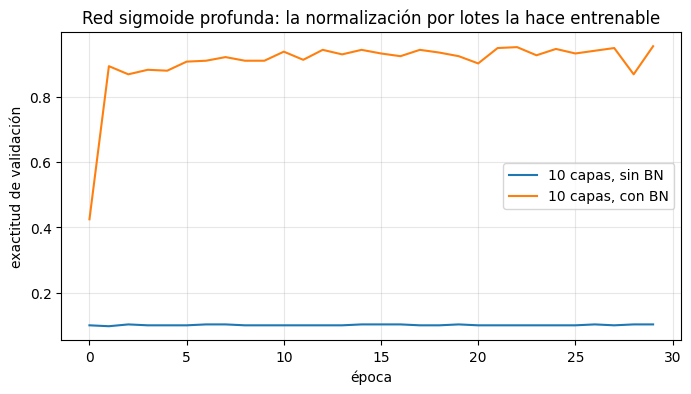

In [9]:
bn_hist = {}
for name, use_bn in [("10 capas, sin BN", False), ("10 capas, con BN", True)]:
    torch.manual_seed(0)
    m = mlp([64] + [128] * 10 + [10], batchnorm=use_bn, act=nn.Sigmoid)
    t0 = time.time()
    bn_hist[name] = train(m, Xtr, ytr, Xdev, ydev, epochs=30, lr=1e-2, batch=64)
    print(f"{name:20s} exactitud de validación tras 30 épocas: {bn_hist[name]['dev'][-1]:.1%}  ({time.time() - t0:.0f} s)")
plt.figure(figsize=(8, 4))
for name, h in bn_hist.items():
    plt.plot(h["dev"], label=name)
plt.xlabel("época"); plt.ylabel("exactitud de validación"); plt.title("Red sigmoide profunda: la normalización por lotes la hace entrenable")
plt.legend(); plt.grid(alpha=0.3); plt.show()

La normalización por lotes también tiene un ligero efecto regularizador (la normalización de cada ejemplo depende del lote aleatorio en el que cae). Los transformers usan la muy parecida **LayerNorm** (notebook 07), que normaliza sobre las características de un solo ejemplo en lugar de sobre el lote, así que funciona igual en entrenamiento y en inferencia y no depende del tamaño del lote.

## 6. Minilotes y calendarios de tasa de aprendizaje

**Tamaño del lote.** El descenso de gradiente con el lote completo calcula el gradiente exacto pero da un solo paso por época. El descenso de gradiente estocástico puro (lote de 1) da muchos pasos baratos y ruidosos. Los minilotes (normalmente de 32 a 1024) están en medio: ejemplos suficientes para aprovechar el hardware vectorizado, pasos suficientes por época para avanzar rápido y un poco de ruido en el gradiente que a menudo ayuda a generalizar.

In [10]:
print(f"{'tamaño lote':>11s} {'pasos/época':>12s} {'exact. val. tras 20 épocas':>27s} {'tiempo':>7s}")
batch_hist = {}
for b in [8, 64, len(ytr)]:
    torch.manual_seed(0)
    m = mlp([64, 128, 10])
    t0 = time.time()
    batch_hist[b] = train(m, Xtr, ytr, Xdev, ydev, epochs=20, lr=1e-3, batch=b)
    print(f"{b:11d} {math.ceil(len(ytr) / b):12d} {batch_hist[b]['dev'][-1]:27.1%} {time.time() - t0:6.1f}s")

tamaño lote  pasos/época  exact. val. tras 20 épocas  tiempo


          8          135                       97.2%    3.6s


         64           17                       95.3%    0.6s
       1077            1                       80.8%    0.1s


Con el mismo número de épocas (la misma cantidad de datos vistos), el entrenamiento con el lote completo va muy por detrás porque solo hizo 20 actualizaciones. Los lotes pequeños avanzaron más, pero cada época cuesta más tiempo real en hardware paralelo. El entrenamiento con lotes grandes suele necesitar una tasa de aprendizaje mayor para compensar.

**Calendarios de tasa de aprendizaje.** Una tasa grande avanza rápido al principio pero después rebota alrededor del mínimo; una pequeña es precisa pero lenta. Los calendarios consiguen ambas cosas:

* **decaimiento escalonado:** dividir la tasa de aprendizaje entre 10 en puntos fijos;
* **calentamiento + decaimiento coseno:** subir linealmente durante el primer pequeño porcentaje de pasos (protegiendo a la red recién inicializada, y a las estadísticas todavía poco fiables de Adam, de actualizaciones enormes al principio) y después seguir media onda de coseno hasta cero. Es lo habitual en los transformers y en los modelos tipo GPT (notebook 08).

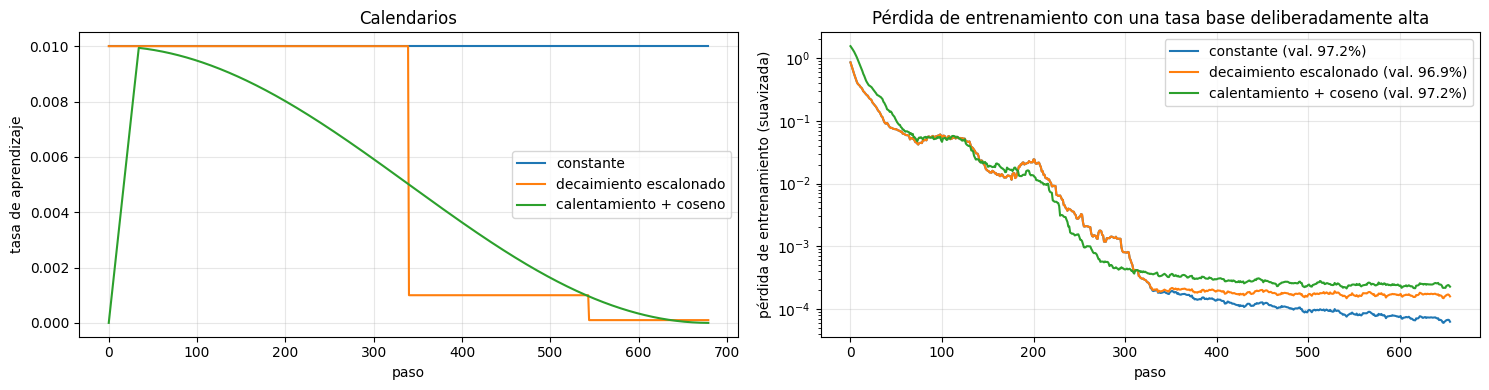

In [11]:
schedules = {
    "constante":         None,
    "decaimiento escalonado":       lambda s, total: 1.0 if s < 0.5 * total else (0.1 if s < 0.8 * total else 0.01),
    "calentamiento + coseno": lambda s, total: min(1.0, s / (0.05 * total)) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))),
}
sched_hist = {}
for name, sch in schedules.items():
    torch.manual_seed(0)
    m = mlp([64, 256, 256, 10])
    sched_hist[name] = train(m, Xtr, ytr, Xdev, ydev, epochs=40, lr=1e-2, batch=64, schedule=sch)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for name, h in sched_hist.items():
    axes[0].plot(h["lr"], label=name)
    axes[1].plot(np.convolve(h["loss"], np.ones(25) / 25, mode="valid"), label=f"{name} (val. {h['dev'][-1]:.1%})")
axes[0].set_xlabel("paso"); axes[0].set_ylabel("tasa de aprendizaje"); axes[0].set_title("Calendarios")
axes[1].set_xlabel("paso"); axes[1].set_ylabel("pérdida de entrenamiento (suavizada)"); axes[1].set_yscale("log"); axes[1].set_title("Pérdida de entrenamiento con una tasa base deliberadamente alta")
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Con una tasa base demasiado alta para estabilizarse, el calendario constante sigue siendo ruidoso; los calendarios con decaimiento usan la misma tasa alta al principio y después se asientan en una pérdida mucho menor.

## 7. Elegir hiperparámetros: búsqueda en cuadrícula frente a búsqueda aleatoria

Una red tiene muchos mandos (tasa de aprendizaje, decaimiento de pesos, anchura, dropout, tamaño de lote…) y **no todos son igual de importantes**. La tasa de aprendizaje casi siempre es la que más importa.

La **búsqueda en cuadrícula** prueba todas las combinaciones de unos pocos valores por mando. La **búsqueda aleatoria** muestrea cada mando de forma independiente. Bergstra y Bengio (2012) explicaron por qué la búsqueda aleatoria suele ganar con el mismo presupuesto: con 9 pruebas en una cuadrícula de 3×3 solo pruebas **3** tasas de aprendizaje distintas; con 9 pruebas aleatorias pruebas 9. Cuando un mando domina, la búsqueda aleatoria lo explora con el triple de densidad.

Dos reglas prácticas: muestrea los parámetros de tipo escala (tasa de aprendizaje, decaimiento de pesos) **en escala logarítmica** y elige con el conjunto de **validación**, nunca con el de prueba.

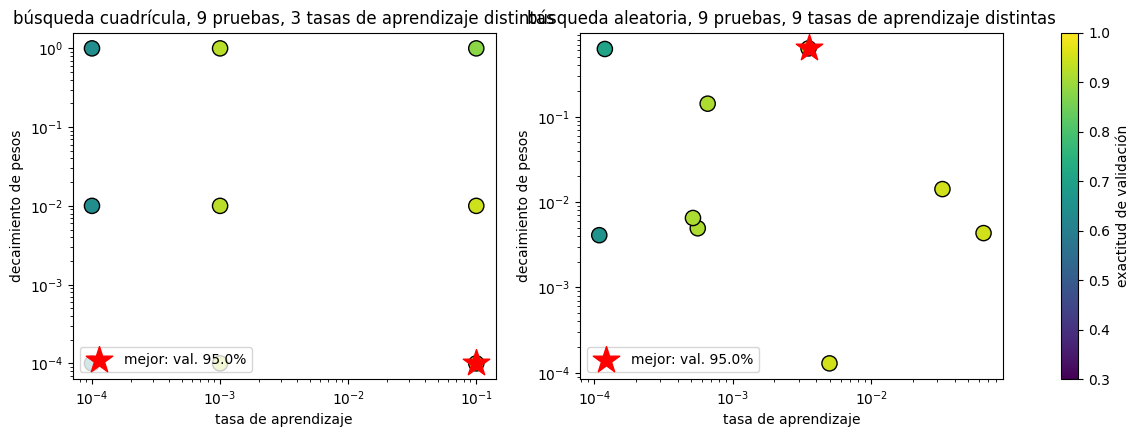

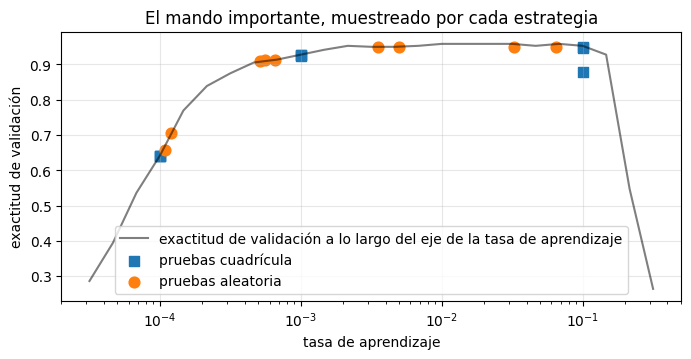

cuadrícula mejor: lr=1.00e-01 wd=1.00e-04  val. 95.0%  →  prueba 93.3% (reportada una vez)
aleatoria  mejor: lr=3.53e-03 wd=6.34e-01  val. 95.0%  →  prueba 94.2% (reportada una vez)


In [12]:
def trial(lr, wd, seed=0):
    torch.manual_seed(seed)
    m = mlp([64, 128, 10])
    train(m, Xtr[:400], ytr[:400], epochs=15, lr=lr, wd=wd, batch=32)
    return accuracy(m, Xdev, ydev), m

grid = [(lr, wd) for lr in [1e-4, 1e-3, 1e-1] for wd in [1e-4, 1e-2, 1]]
rng = np.random.default_rng(1)
rand = [(10 ** rng.uniform(-4.5, -0.5), 10 ** rng.uniform(-4, 0)) for _ in range(9)]
search = {"cuadrícula": [(lr, wd, *trial(lr, wd)) for lr, wd in grid],
          "aleatoria": [(lr, wd, *trial(lr, wd)) for lr, wd in rand]}

# the dense "truth" along the important axis, to see what each search could have found
lrs = np.logspace(-4.5, -0.5, 25)
dense = [trial(lr, 1e-3)[0] for lr in lrs]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (name, res) in zip(axes, search.items()):
    sc = ax.scatter([r[0] for r in res], [r[1] for r in res], c=[r[2] for r in res], cmap="viridis", vmin=0.3, vmax=1, s=120, edgecolors="k")
    best = max(res, key=lambda r: r[2])
    ax.scatter([best[0]], [best[1]], marker="*", s=400, color="red", label=f"mejor: val. {best[2]:.1%}")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("tasa de aprendizaje"); ax.set_ylabel("decaimiento de pesos")
    ax.set_title(f"búsqueda {name}, 9 pruebas, {len(set(round(r[0], 12) for r in res))} tasas de aprendizaje distintas"); ax.legend(loc="lower left")
plt.colorbar(sc, ax=axes, label="exactitud de validación"); plt.show()

plt.figure(figsize=(8, 3.5))
plt.semilogx(lrs, dense, "k-", alpha=0.5, label="exactitud de validación a lo largo del eje de la tasa de aprendizaje")
for name, marker in [("cuadrícula", "s"), ("aleatoria", "o")]:
    plt.scatter([r[0] for r in search[name]], [r[2] for r in search[name]], marker=marker, s=60, label=f"pruebas {name}")
plt.xlabel("tasa de aprendizaje"); plt.ylabel("exactitud de validación"); plt.legend(); plt.grid(alpha=0.3); plt.title("El mando importante, muestreado por cada estrategia"); plt.show()

for name, res in search.items():
    lr, wd, dev, m = max(res, key=lambda r: r[2])
    print(f"{name:10s} mejor: lr={lr:.2e} wd={wd:.2e}  val. {dev:.1%}  →  prueba {accuracy(m, Xte, yte):.1%} (reportada una vez)")

Con 9 pruebas, aquí ambas estrategias dieron por casualidad con configuraciones igual de buenas, pero mira la segunda gráfica: la cuadrícula solo probó tres tasas de aprendizaje, una de ellas demasiado alta, mientras que la búsqueda aleatoria cubrió el rango útil. Con más mandos, o con una zona óptima más estrecha, esa cobertura es la que hace que la búsqueda aleatoria gane en promedio (el ejercicio 4 lo mide). En proyectos reales el presupuesto es mayor y la búsqueda más inteligente (búsqueda aleatoria de lo grueso a lo fino, optimización bayesiana o, sencillamente, copiar los hiperparámetros de un modelo publicado de tamaño parecido), pero los principios se mantienen: escalas logarítmicas, aleatoria mejor que cuadrícula, elegir con validación y reportar la prueba una sola vez.

## 8. Estrategia: ¿en qué debería trabajar ahora?

Muchos meses perdidos en aprendizaje automático vienen de mejorar lo que no era. Dos hábitos ayudan.

### Análisis de errores

Mira los errores del conjunto de validación y **cuéntalos** por categoría antes de decidir qué corregir. Si el 40 % de los errores son una confusión y el 2 % otra, la primera merece una semana de trabajo y la segunda no (su *techo* es una mejora del 2 %, por perfectamente que la resuelvas). Lleva una hora y a menudo cambia el plan.

exactitud de validación 98.1%: 7 errores de 360

confusiones más frecuentes (real → predicho), como proporción de todos los errores:
  8 → 1:  1  (14%)
  5 → 1:  1  (14%)
  3 → 8:  1  (14%)
  7 → 9:  1  (14%)
  4 → 8:  1  (14%)
  0 → 4:  1  (14%)


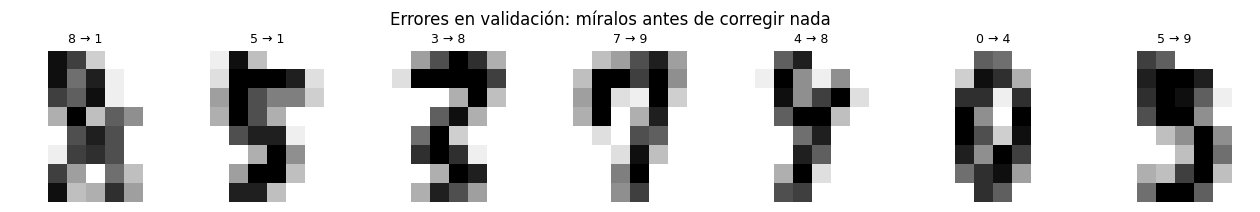

In [13]:
torch.manual_seed(0)
model = mlp([64, 256, 256, 10], dropout=0.3)
train(model, Xtr, ytr, Xdev, ydev, epochs=60, lr=1e-3, wd=1e-2, batch=32, keep_best=True)
model.eval()
with torch.no_grad():
    pred = model(Xdev).argmax(1)
wrong = (pred != ydev).nonzero().ravel()
print(f"exactitud de validación {accuracy(model, Xdev, ydev):.1%}: {len(wrong)} errores de {len(ydev)}\n")

from collections import Counter
pairs = Counter((ydev[i].item(), pred[i].item()) for i in wrong)
print("confusiones más frecuentes (real → predicho), como proporción de todos los errores:")
for (t, p), n in pairs.most_common(6):
    print(f"  {t} → {p}: {n:2d}  ({n / len(wrong):.0%})")

fig, axes = plt.subplots(1, min(10, len(wrong)), figsize=(16, 2), squeeze=False)
for ax, i in zip(axes[0], wrong[:10]):
    ax.imshow(Xdev[i].reshape(8, 8), cmap="gray_r"); ax.axis("off"); ax.set_title(f"{ydev[i].item()} → {pred[i].item()}", fontsize=9)
plt.suptitle("Errores en validación: míralos antes de corregir nada", y=1.08); plt.show()

Con solo un puñado de errores de validación, ninguna categoría domina, y eso ya es un hallazgo en sí mismo: este modelo está cerca del punto en el que la siguiente mejora necesita **más datos de validación** incluso para poder medirse. El análisis de errores rinde más cuando hay decenas o cientos de errores que clasificar.

### Cuando los datos de entrenamiento y los reales no coinciden

A menudo los datos que puedes reunir en grandes cantidades no son exactamente los que encontrarás en producción: fotos de la web frente a fotos de la cámara de un teléfono, audio de estudio frente a un coche ruidoso o, aquí, **dígitos escaneados limpios para entrenar** frente a **dígitos borrosos y ruidosos de un escáner barato** en producción.

Regla número uno: los conjuntos de validación y prueba deben parecerse a **producción**, porque ese es el objetivo. Pero entonces la brecha entre el error de entrenamiento y el de validación mezcla dos causas: la varianza *y* el cambio de distribución. Para separarlas, se reserva un conjunto de **entrenamiento-validación** (train-dev): misma distribución que el entrenamiento, pero sin entrenar con él.

| Brecha | Significado |
|---|---|
| error de entrenamiento − error de referencia | sesgo evitable |
| error de train-dev − error de entrenamiento | varianza |
| error de validación − error de train-dev | **desajuste de datos** |

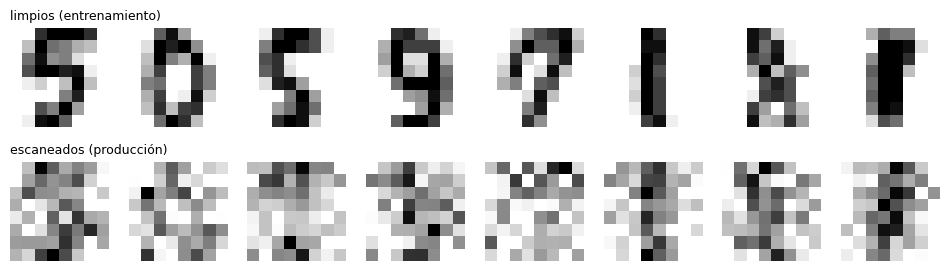

entrenado solo con dígitos limpios:
  entrenamiento  0.0%   train-dev  2.5%   validación (escaneados) 65.0%
  → varianza +2.5%   desajuste de datos +62.5%


In [14]:
def scanner(x, seed):
    # simula un escáner barato: desenfoque, tinta desvaída y ruido moteado
    g = torch.Generator().manual_seed(seed)
    img = x.reshape(-1, 1, 8, 8)
    img = F.avg_pool2d(F.pad(img, (1, 1, 1, 1), mode="replicate"), 3, stride=1)       # desenfoque 3x3
    img = img * (0.5 + 0.5 * torch.rand(len(img), 1, 1, 1, generator=g))               # tinta desvaída
    img = img + 0.25 * torch.randn(img.shape, generator=g)                             # moteado
    return img.clamp(0, 1).reshape(len(x), 64)

# datos de entrenamiento: limpios (más una porción train-dev reservada, de la misma distribución limpia)
Xc_tr, yc_tr, Xc_trdev, yc_trdev = Xtr[:800], ytr[:800], Xtr[800:], ytr[800:]
# validación y prueba: datos de producción, es decir, escaneados
Xs_dev, Xs_te = scanner(Xdev, 1), scanner(Xte, 2)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for k in range(8):
    axes[0, k].imshow(Xdev[k].reshape(8, 8), cmap="gray_r"); axes[1, k].imshow(Xs_dev[k].reshape(8, 8), cmap="gray_r")
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].set_title("limpios (entrenamiento)", loc="left", fontsize=9); axes[1, 0].set_title("escaneados (producción)", loc="left", fontsize=9)
plt.show()

def report(model, label):
    e_tr = 1 - accuracy(model, Xc_tr, yc_tr); e_trdev = 1 - accuracy(model, Xc_trdev, yc_trdev); e_dev = 1 - accuracy(model, Xs_dev, ydev)
    print(f"{label}\n  entrenamiento {e_tr:5.1%}   train-dev {e_trdev:5.1%}   validación (escaneados) {e_dev:5.1%}")
    print(f"  → varianza {e_trdev - e_tr:+.1%}   desajuste de datos {e_dev - e_trdev:+.1%}")

torch.manual_seed(0)
clean_model = mlp([64, 256, 256, 10], dropout=0.3)
train(clean_model, Xc_tr, yc_tr, epochs=60, lr=1e-3, wd=1e-2, batch=32)
report(clean_model, "entrenado solo con dígitos limpios:")

El diagnóstico no deja dudas: la varianza es pequeña y el problema es el desajuste de datos. Más datos limpios o más regularización no ayudarían. Lo que ayuda es hacer que los datos de entrenamiento **se parezcan más a producción**. Aquí sabemos más o menos qué hace el escáner, así que podemos **sintetizar** datos de entrenamiento parecidos a los de producción a partir de las imágenes limpias (la misma idea que el aumento de datos). En proyectos reales, en cambio, podrías reunir una pequeña cantidad de datos reales de producción y añadirlos al conjunto de entrenamiento.

In [15]:
X_aug = torch.cat([Xc_tr, scanner(Xc_tr, 10), scanner(Xc_tr, 11)])     # limpios + dos copias "escaneadas" sintéticas
y_aug = torch.cat([yc_tr, yc_tr, yc_tr])
torch.manual_seed(0)
aug_model = mlp([64, 256, 256, 10], dropout=0.3)
train(aug_model, X_aug, y_aug, epochs=30, lr=1e-3, wd=1e-2, batch=32)
report(aug_model, "entrenado con dígitos limpios + escaneados sintéticos:")
print(f"\ncomprobación final en el conjunto de PRUEBA escaneado sin tocar: solo limpios {accuracy(clean_model, Xs_te, yte):.1%}  frente a  con síntesis {accuracy(aug_model, Xs_te, yte):.1%}")

entrenado con dígitos limpios + escaneados sintéticos:
  entrenamiento  0.6%   train-dev  2.9%   validación (escaneados) 41.1%
  → varianza +2.3%   desajuste de datos +38.2%

comprobación final en el conjunto de PRUEBA escaneado sin tocar: solo limpios 36.4%  frente a  con síntesis 51.1%


Una advertencia de la práctica: los datos sintéticos solo corrigen el desajuste que *modelaste*. Si el escáner real también gira las páginas y nuestra simulación no, el modelo seguirá fallando con las rotaciones, e incluso puede sobreajustarse a las peculiaridades de la simulación. Confirma siempre con datos reales de producción en los conjuntos de validación y prueba.

## Ideas clave

* El objetivo es un error bajo con datos **no vistos**. Usa entrenamiento / validación / prueba, decide todo con validación y reporta la prueba una sola vez.
* Compara el error de entrenamiento con una referencia y con el error de validación para decidir entre soluciones para el **sesgo** (modelo más grande, más entrenamiento) y para la **varianza** (datos, regularización).
* El **decaimiento de pesos, el dropout y la parada temprana** combaten el sobreajuste y se combinan bien.
* La **normalización por lotes** mantiene bien escaladas las activaciones y permite entrenar redes profundas con tasas de aprendizaje más altas.
* **Minilotes** más un **calendario con calentamiento y decaimiento** son la receta por defecto para entrenar.
* Busca hiperparámetros **de forma aleatoria y en escalas logarítmicas**; la tasa de aprendizaje es la que más importa.
* Haz **análisis de errores** antes de decidir qué corregir, y usa un conjunto **train-dev** para separar la varianza del **desajuste de datos**.

## Ejercicios

1. En la sección 2, repite el barrido de capacidad con 2.000 puntos de entrenamiento en lugar de 200. ¿Dónde empieza ahora el sobreajuste?
2. En la sección 4, barre el decaimiento de pesos sobre `[0.01, 0.1, 0.5, 2, 5]`. Dibuja la exactitud de validación frente al decaimiento: ¿dónde está la zona óptima y qué pasa más allá?
3. Sustituye `nn.BatchNorm1d` por `nn.LayerNorm` en la red sigmoide de 10 capas. ¿Ayuda igual?
4. Dale 25 pruebas a la búsqueda aleatoria y otras 25 a la búsqueda en cuadrícula. Repite con 5 semillas distintas para el muestreador aleatorio: ¿cuántas veces gana la búsqueda aleatoria?
5. Haz que el escáner también desplace cada imagen un píxel en una dirección aleatoria, pero deja sin cambios los datos de entrenamiento sintetizados. ¿Qué le pasa a la cifra del desajuste de datos?